# Transactions and ACID Principles

A **transaction** is a group of operations that the database treats as one unit: either all of them happen, or none. Transactions keep data correct when programs fail and when many users write at the same time.

**After this lesson you can:**

1. Explain the four ACID properties.
2. Use `BEGIN`, `COMMIT`, `ROLLBACK` and savepoints.
3. Reproduce a **lost update** with two concurrent connections and prevent it.
4. Explain isolation levels and observe a deadlock.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. ACID

| Property | Meaning | Example |
| :--- | :--- | :--- |
| **Atomicity** | all or nothing | a transfer debits one account and credits another, or does neither |
| **Consistency** | constraints hold before and after | a balance can never become negative if a `CHECK` forbids it |
| **Isolation** | concurrent transactions do not see each other's half-done work | two cashiers do not sell the last ticket twice |
| **Durability** | after `COMMIT`, the data survives a crash | PostgreSQL writes the change to its write-ahead log (WAL) first |

In [2]:
run("""
DROP TABLE IF EXISTS account;
CREATE TABLE account (id text PRIMARY KEY, balance numeric(10,2) NOT NULL CHECK (balance >= 0));
INSERT INTO account VALUES ('ayse', 100), ('mert', 50)
""")

def transfer(src: str, dst: str, amount: float) -> str:
    try:
        with lab.begin() as conn:                     # one transaction
            conn.execute(text("UPDATE account SET balance = balance + :a WHERE id = :d"), {"a": amount, "d": dst})
            conn.execute(text("UPDATE account SET balance = balance - :a WHERE id = :s"), {"a": amount, "s": src})
        return "committed"
    except Exception as err:
        return f"rolled back ({type(err.orig).__name__})"

print("transfer 30 :", transfer("ayse", "mert", 30))
print("transfer 500:", transfer("ayse", "mert", 500))    # would make ayse's balance negative
lq("SELECT * FROM account ORDER BY id")

transfer 30 : committed
transfer 500: rolled back (CheckViolation)


,id,balance
0,ayse,70.0
1,mert,80.0


The second transfer first credited Mert, then failed on the debit (the `CHECK` constraint). The whole transaction rolled back, so Mert did not receive money that never left Ayse's account: **atomicity** and **consistency**.

## 2. Savepoints

A **savepoint** marks a point inside a transaction. `ROLLBACK TO SAVEPOINT` undoes the work after that point but keeps the work before it. Batch jobs use savepoints to skip one bad record without losing the whole batch.

In [3]:
run("DROP TABLE IF EXISTS imported; CREATE TABLE imported (id int PRIMARY KEY, qty int CHECK (qty > 0))")
records = [(1, 5), (2, -1), (3, 7), (3, 9), (4, 2)]
skipped = []
with lab.begin() as conn:
    for rid, qty in records:
        sp = conn.begin_nested()                       # SAVEPOINT
        try:
            conn.execute(text("INSERT INTO imported VALUES (:i, :q)"), {"i": rid, "q": qty})
            sp.commit()
        except Exception as err:
            sp.rollback()                              # ROLLBACK TO SAVEPOINT
            skipped.append((rid, qty, type(err.orig).__name__))
print("skipped:", skipped)
lq("SELECT * FROM imported ORDER BY id")

skipped: [(2, -1, 'CheckViolation'), (3, 9, 'UniqueViolation')]


,id,qty
0,1,5
1,3,7
2,4,2


## 3. Concurrency: the Lost Update

Two clients read a value, both compute a new value from it, and both write it back. The second write overwrites the first one: one update is **lost**. The experiment runs 8 threads; each thread adds 1 to a counter 25 times with a naive *read → compute → write* pattern.

In [4]:
import threading
import time

def reset_counter():
    run("DROP TABLE IF EXISTS counter; CREATE TABLE counter (id int PRIMARY KEY, value int); INSERT INTO counter VALUES (1, 0)")

def naive_worker(n):
    for _ in range(n):
        with lab.begin() as conn:
            v = conn.execute(text("SELECT value FROM counter WHERE id = 1")).scalar()
            time.sleep(0.001)                                          # some application work
            conn.execute(text("UPDATE counter SET value = :v WHERE id = 1"), {"v": v + 1})

def locking_worker(n):
    for _ in range(n):
        with lab.begin() as conn:
            v = conn.execute(text("SELECT value FROM counter WHERE id = 1 FOR UPDATE")).scalar()   # row lock
            time.sleep(0.001)
            conn.execute(text("UPDATE counter SET value = :v WHERE id = 1"), {"v": v + 1})

def atomic_worker(n):
    for _ in range(n):
        with lab.begin() as conn:
            conn.execute(text("UPDATE counter SET value = value + 1 WHERE id = 1"))               # one statement

results = {}
for name, worker in [("read-compute-write", naive_worker), ("SELECT ... FOR UPDATE", locking_worker),
                     ("UPDATE value = value + 1", atomic_worker)]:
    reset_counter()
    threads = [threading.Thread(target=worker, args=(25,)) for _ in range(8)]
    t = time.perf_counter()
    for th in threads: th.start()
    for th in threads: th.join()
    results[name] = (lq("SELECT value FROM counter")["value"][0], time.perf_counter() - t)
    print(f"{name:<26} final value {results[name][0]:>3} of 200 expected, {results[name][1]:.2f} s")

read-compute-write         final value  25 of 200 expected, 5.40 s


SELECT ... FOR UPDATE      final value 200 of 200 expected, 6.36 s


UPDATE value = value + 1   final value 200 of 200 expected, 6.16 s


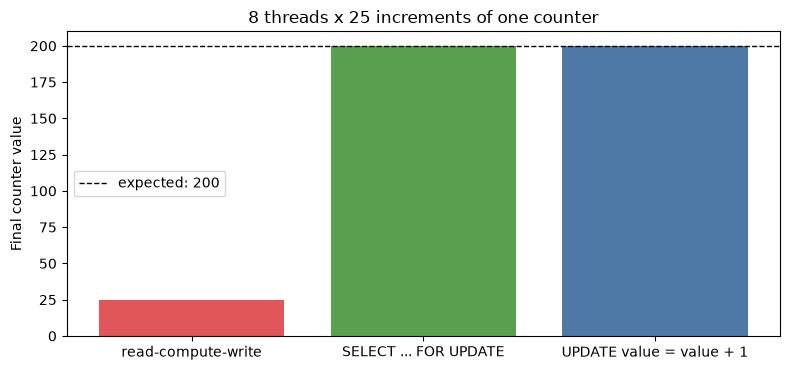

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(results)
ax.bar(names, [results[n][0] for n in names], color=["#E15759", "#59A14F", "#4E79A7"])
ax.axhline(200, color="black", ls="--", lw=1, label="expected: 200")
ax.set(title="8 threads x 25 increments of one counter", ylabel="Final counter value")
ax.legend()
plt.tight_layout()
plt.show()

The naive version loses many updates. Two fixes work:

1. **Pessimistic locking:** `SELECT ... FOR UPDATE` locks the row; other transactions wait until the lock is released.
2. **Atomic statements:** `UPDATE ... SET value = value + 1` lets the database do the read and the write in one step.

A third common fix is **optimistic locking**: add a `version` column and update only `WHERE version = :old_version`; retry if no row changed.

## 4. Isolation Levels

| Level (PostgreSQL) | Prevents | Allows |
| :--- | :--- | :--- |
| `READ COMMITTED` (default) | dirty reads | non-repeatable reads: the same query can return different results in one transaction |
| `REPEATABLE READ` | non-repeatable reads | — (in PostgreSQL also prevents phantoms), but conflicting writes fail with a serialization error |
| `SERIALIZABLE` | every anomaly: the result equals some serial order | more transactions fail and must be retried |

The cell shows a non-repeatable read: transaction A reads a balance twice, while transaction B commits a change between the two reads.

In [6]:
def two_reads(level: str) -> tuple:
    run("UPDATE account SET balance = 70 WHERE id = 'ayse'")
    a = lab.connect().execution_options(isolation_level=level)
    with a.begin():
        first = a.execute(text("SELECT balance FROM account WHERE id = 'ayse'")).scalar()
        with lab.begin() as b:                                   # another client commits a change
            b.execute(text("UPDATE account SET balance = 10 WHERE id = 'ayse'"))
        second = a.execute(text("SELECT balance FROM account WHERE id = 'ayse'")).scalar()
    a.close()
    return float(first), float(second)

for level in ("READ COMMITTED", "REPEATABLE READ"):
    f, s = two_reads(level)
    print(f"{level:<16} first read {f:5.1f}, second read {s:5.1f} -> {'changed' if f != s else 'stable snapshot'}")

READ COMMITTED   first read  70.0, second read  10.0 -> changed
REPEATABLE READ  first read  70.0, second read  70.0 -> stable snapshot


## 5. Deadlocks

A **deadlock** happens when transaction A waits for a lock held by B, and B waits for a lock held by A. PostgreSQL detects the cycle after `deadlock_timeout` (1 second by default) and aborts one transaction. The cell creates a deadlock on purpose.

In [7]:
errors = []
def tx(first: str, second: str, barrier: threading.Barrier):
    try:
        with lab.begin() as conn:
            conn.execute(text("UPDATE account SET balance = balance + 1 WHERE id = :i"), {"i": first})
            barrier.wait()                                          # both hold their first lock now
            conn.execute(text("UPDATE account SET balance = balance + 1 WHERE id = :i"), {"i": second})
    except Exception as err:
        errors.append(type(err.orig).__name__)

barrier = threading.Barrier(2)
t1 = threading.Thread(target=tx, args=("ayse", "mert", barrier))
t2 = threading.Thread(target=tx, args=("mert", "ayse", barrier))
t1.start(); t2.start(); t1.join(); t2.join()
print("aborted transactions:", errors)

aborted transactions: ['DeadlockDetected']


One transaction was aborted with `DeadlockDetected`; the other completed. Prevention: always lock rows **in the same order** (for example by id), keep transactions short, and retry transactions that fail with a deadlock or serialization error.

*Insight: Put every multi-step change in one transaction, prefer atomic statements (`SET x = x + 1`) or explicit locks over read-compute-write, and design code to retry transactions that the database aborts.*

## Real-World Use Case or Analogy

A transaction is like a **bank transfer at the counter**: the clerk completes both entries (debit and credit) or tears up the form. The lost update is like two clerks who both read "10 tickets left" from a whiteboard, each sell one, and each write "9" — one ticket was sold twice. `FOR UPDATE` is a clerk who takes the marker so nobody else can write until they are finished.

Payment systems, booking platforms and inventory services depend on these guarantees. In data engineering, loading a batch inside one transaction means a failed load leaves no half-written data behind (M11).